In [1]:
import numpy as np
import pandas as pd
import os, warnings 
warnings.filterwarnings('ignore') 
from setup import *

In [2]:
thre_count = 15
def extract_specific_features(df_diff, df_counts, label, thre_diff=.3, thre_pval=3, ntop=5, nbottom=5):
    """
    Extract subtype-specific features based on significance, frequency, and differential expression.
    
    Parameters:
    df_diff: DataFrame with differential expression results (must contain 'subtype', label, 'neg_log_p_adj', 'diff')
    df_counts: DataFrame with count data (must contain 'subtype', label, 'count')
    label: str, the feature label column name (e.g., 'TF')
    thre_count: int, minimum count threshold for feature inclusion
    
    Returns:
    DataFrame with subtype-specific features meeting all criteria, including all samples for selected features
    """
    # Create a list to store results for each subtype
    subtype_specific_features = []
    
    # Get unique subtypes
    unique_subtypes = df_diff['subtype'].unique()
    
    for subtype in unique_subtypes:
        # First, get features that appear in at least thre_count samples for this subtype
        subtype_feature_counts = df_counts[
            (df_counts['subtype'] == subtype) & 
            (df_counts['count'] >= thre_count)
        ][label].tolist()
        
        if not subtype_feature_counts:
            continue
        
        # Now filter the differential expression dataframe for this subtype
        # Only filter by significance and count here, NOT by diff.abs()
        subtype_df = df_diff[
            (df_diff['subtype'] == subtype) & 
            (df_diff[label].isin(subtype_feature_counts)) &
            (df_diff['neg_log_p_adj'] > thre_pval)
        ].copy()
        
        if not subtype_df.empty:
            # Get top 3 features with largest diff (most upregulated)
            top_features = subtype_df.nlargest(ntop, 'diff')[label].unique().tolist()
            
            # Get bottom 2 features with smallest diff (most downregulated)
            bottom_features = subtype_df.nsmallest(nbottom, 'diff')[label].unique().tolist()
            
            # Combine and remove duplicates
            selected_features = list(set(top_features + bottom_features))
            
            if selected_features:
                # Get ALL samples for these selected features in this subtype
                # BUT now filter to only include samples where diff.abs() > 1
                selected_df = df_diff[
                    (df_diff['subtype'] == subtype) & 
                    (df_diff[label].isin(selected_features)) &
                    (df_diff['diff'].abs() > thre_diff)  # Apply the diff filter here
                ].copy()
                
                # Verify that each selected feature still appears in enough samples
                valid_features = []
                for feature in selected_features:
                    feature_count = len(selected_df[selected_df[label] == feature])
                    if feature_count >= thre_count:
                        valid_features.append(feature)
                
                if valid_features:
                    # Filter to only include features that still meet the count threshold
                    selected_df = selected_df[selected_df[label].isin(valid_features)]
                    subtype_specific_features.append(selected_df)
    
    # Combine all results into a single DataFrame
    if subtype_specific_features:
        final_result = pd.concat(subtype_specific_features, ignore_index=True)
        return final_result
    else:
        return pd.DataFrame()

In [3]:
def filter_rows(df_diff, final_result, key):
    existing_pairs = set(zip(final_result[key], final_result['subtype']))
    mask = df_diff.apply(lambda row: (row[key], row['subtype']) in existing_pairs, axis=1)
    filtered_df = df_diff[mask]
    return filtered_df

## MP-specific TFs

In [4]:
df_tf_diff = pd.read_csv('dataframes/across_metaprogram/tf_score.csv', index_col=0)
df_tf_counts = (
    df_tf_diff.groupby('subtype')['TF']
    .value_counts()
    .reset_index(name='count')
)

In [5]:
df_tf_diff

,sample,TF,subtype,TFa,p_adj,neg_log_p_adj,rank,abs_TFa,diff
0,MGH258,ATF3,AC,0.515660,1.675361e-05,4.775889,0,0.515660,0.541871
1,MGH258,KLF10,Chromatin.Reg,0.898913,2.562594e-09,8.574695,0,0.898913,0.926991
2,MGH258,STAT2,Inflammatory.Mac,0.752748,5.167208e-33,10.000000,0,0.752748,0.833790
3,MGH258,FLI1,MES,0.554911,9.224163e-12,9.961681,0,0.554911,0.599347
4,MGH258,HIF1A,MES.Ast,0.953233,4.400021e-36,10.000000,0,0.953233,1.037162
...,...,...,...,...,...,...,...,...,...
76053,ZH916inf,NR2C2,Neuron,-1.123943,8.301650e-43,10.000000,186,1.123943,-1.345372
76054,ZH916inf,ELK4,OPC,-0.538461,2.045580e-01,0.689183,186,0.538461,-0.558756
76055,ZH916inf,KLF10,Oligo,-0.522265,8.641509e-13,9.996263,186,0.522265,-0.631159
76056,ZH916inf,STAT4,Prolif.Metab,-0.497088,4.567990e-01,0.340275,186,0.497088,-0.518880


<Axes: >

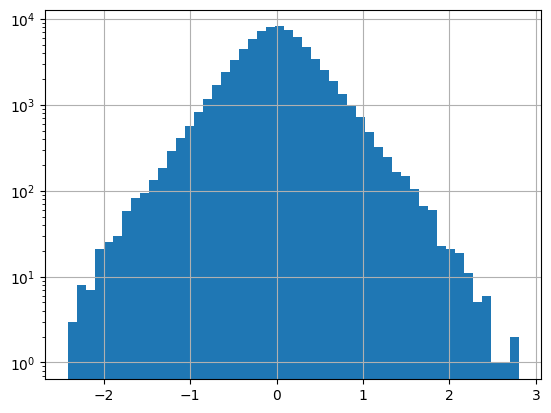

In [6]:
df_tf_diff['diff'].hist(bins=50, log=True)

In [7]:
final_result_tfs = extract_specific_features(df_tf_diff, df_tf_counts, 'TF', thre_pval=3, thre_diff=0.3)
final_result_tfs

,sample,TF,subtype,TFa,p_adj,neg_log_p_adj,rank,abs_TFa,diff
0,MGH258,SREBF2,AC,0.453035,1.453836e-04,3.837484,2,0.453035,0.476063
1,MGH258,SOX2,AC,0.298573,8.317063e-03,2.080030,26,0.298573,0.313750
2,MGH258,DBP,AC,-0.335331,1.908860e-03,2.719226,194,0.335331,-0.352376
3,MGH258,PAX6,AC,-0.290927,8.255773e-04,3.083242,196,0.290927,-0.305715
4,UKF243,ETV5,AC,-0.337541,5.561347e-12,9.976495,190,0.337541,-0.410720
...,...,...,...,...,...,...,...,...,...
1144,ZH916inf,ZNF281,Neuron,0.732346,3.546677e-23,10.000000,14,0.732346,0.876626
1145,ZH916inf,REST,Neuron,0.733528,4.121818e-21,10.000000,16,0.733528,0.878041
1146,ZH916inf,PAX6,Neuron,0.357607,7.037881e-11,9.768584,39,0.357607,0.428059
1147,ZH916inf,SMAD3,Neuron,-0.254319,2.821634e-04,3.549499,129,0.254319,-0.304422


In [8]:
filtered_df = filter_rows(df_tf_diff, final_result_tfs, key = 'TF')
filtered_df

,sample,TF,subtype,TFa,p_adj,neg_log_p_adj,rank,abs_TFa,diff
6,MGH258,MEF2C,Mac,0.753543,5.640818e-46,10.000000,0,0.753543,0.872233
11,MGH258,NR3C1,Vasc,0.627694,1.130669e-44,10.000000,0,0.627694,0.741303
17,MGH258,HIF1A,MES.Hyp,0.886400,3.371764e-13,9.998538,1,0.886400,0.918798
18,MGH258,RFX3,Mac,0.763700,9.902436e-46,10.000000,1,0.763700,0.883990
24,MGH258,SREBF2,AC,0.453035,1.453836e-04,3.837484,2,0.453035,0.476063
...,...,...,...,...,...,...,...,...,...
75851,ZH916inf,MEIS1,Chromatin.Reg,-0.314950,1.458216e-02,1.836178,171,0.314950,-0.349459
75977,ZH916inf,HIF1A,Oligo,-0.357753,9.925902e-06,5.003226,180,0.357753,-0.432346
75994,ZH916inf,MAZ,Chromatin.Reg,-0.506564,4.498772e-05,4.346905,182,0.506564,-0.562069
76021,ZH916inf,ZNF84,Inflammatory.Mac,-1.215264,1.993485e-34,10.000000,184,1.215264,-1.394072


In [9]:
# final_result_tfs.to_csv('dataframes/mp_specific_tfs.csv')
filtered_df.to_csv('dataframes/mp_specific_tfs.csv')

## MP-specific Pathways

In [10]:
df_pw_diff = pd.read_csv('dataframes/across_metaprogram/pw_score.csv', index_col=0)
df_pw_diff['PW'] = [hallmarks[x] for x in df_pw_diff['PW']]
df_pw_counts = (
    df_pw_diff.groupby('subtype')['PW']
    .value_counts()
    .reset_index(name='count')
)

In [11]:
final_result_pws = extract_specific_features(df_pw_diff, df_pw_counts, 'PW')
final_result_pws

,sample,PW,subtype,PWa,p_adj,neg_log_p_adj,rank,abs_PWa,diff
0,MGH258,TNFA Signaling via NFKB,AC,-0.400415,4.111790e-03,2.385969,44,0.400415,-0.420769
1,UKF243,Cholesterol Homeostasis,AC,0.750485,8.057399e-49,10.000000,0,0.750485,0.913192
2,UKF243,Oxidative phosphorylation,AC,0.518106,4.835444e-29,10.000000,11,0.518106,0.630432
3,UKF243,Angiogenesis,AC,0.337845,6.001203e-10,9.154827,30,0.337845,0.411090
4,UKF248,Oxidative phosphorylation,AC,0.350394,2.576133e-09,8.572492,1,0.350394,0.391487
...,...,...,...,...,...,...,...,...,...
1154,ZH916inf,INFG Response,Neuron,0.892913,1.500169e-29,10.000000,13,0.892913,1.068826
1155,ZH916inf,Estrogen Response Early,Neuron,0.988652,1.291575e-25,10.000000,19,0.988652,1.183427
1156,ZH916inf,Coagulation,Neuron,-0.984975,1.189270e-32,10.000000,39,0.984975,-1.179026
1157,ZH916inf,IL6/JAK/STAT3 Signaling,Neuron,-1.385266,2.245831e-46,10.000000,42,1.385266,-1.658179


In [12]:
filtered_df = filter_rows(df_pw_diff, final_result_pws, key = 'PW')
filtered_df

,sample,PW,subtype,PWa,p_adj,neg_log_p_adj,rank,abs_PWa,diff
3,MGH258,TNFA Signaling via NFKB,MES,0.567189,5.184942e-11,9.818587,0,0.567189,0.612609
6,MGH258,Allograft Rejection,Mac,0.696160,2.125925e-37,10.000000,0,0.696160,0.805811
8,MGH258,ROS,Oligo,1.107372,5.846030e-143,10.000000,0,1.107372,1.409382
11,MGH258,EMT,Vasc,0.768651,1.473373e-56,10.000000,0,0.768651,0.907771
14,MGH258,INFG Response,Inflammatory.Mac,0.777336,2.429907e-35,10.000000,1,0.777336,0.861025
...,...,...,...,...,...,...,...,...,...
15642,ZH916inf,Angiogenesis,Neuron,-1.411471,4.939865e-51,10.000000,43,1.411471,-1.689546
15647,ZH916inf,TNFA Signaling via NFKB,AC,-0.357198,1.995757e-01,0.699892,44,0.357198,-0.379146
15648,ZH916inf,MYC Targets v1,Chromatin.Reg,-1.052466,1.366716e-24,10.000000,44,1.052466,-1.167787
15651,ZH916inf,ROS,MES.Ast,-0.404824,1.224006e-01,0.912216,44,0.404824,-0.415192


In [13]:
# final_result_pws.to_csv('dataframes/mp_specific_pws.csv')
filtered_df.to_csv('dataframes/mp_specific_pws.csv')

## MP-specific Drugs

In [14]:
df_d2c_diff = pd.read_csv('dataframes/across_metaprogram/d2c_score.csv', index_col=0)
df_d2c_counts = (
    df_d2c_diff.groupby('subtype')['DC']
    .value_counts()
    .reset_index(name='count')
)

In [15]:
final_result_dcs = extract_specific_features(df_d2c_diff, df_d2c_counts, 'DC', ntop=5, nbottom=0)
final_result_dcs

,sample,DC,subtype,DCa,p_adj,neg_log_p_adj,rank,abs_DCa,diff
0,MGH258,CHEMBL1111|AMBRISENTAN,AC,0.509710,1.222342e-05,4.912804,1,0.509710,0.535619
1,MGH258,CHEMBL957|BOSENTAN,AC,0.509710,1.222342e-05,4.912804,2,0.509710,0.535619
2,UKF243,CHEMBL1111|AMBRISENTAN,AC,0.890874,2.859878e-58,10.000000,0,0.890874,1.084018
3,UKF243,CHEMBL957|BOSENTAN,AC,0.890874,2.859878e-58,10.000000,1,0.890874,1.084018
4,UKF251,CHEMBL1111|AMBRISENTAN,AC,0.286715,5.465112e-01,0.262401,18,0.286715,0.305241
...,...,...,...,...,...,...,...,...,...
540,ZH916inf,CHEMBL4297229|PRABOTULINUMTOXIN A,Neuron,1.212134,1.732142e-40,10.000000,3,1.212134,1.450938
541,ZH916inf,CHEMBL2108570|ABOBOTULINUMTOXINA,Neuron,1.212134,1.732142e-40,10.000000,4,1.212134,1.450938
542,ZH916inf,CHEMBL2108035|INCOBOTULINUMTOXINA,Neuron,1.212134,1.732142e-40,10.000000,5,1.212134,1.450938
543,ZH916inf,CHEMBL1201574|ONABOTULINUMTOXINA,Neuron,1.212134,1.732142e-40,10.000000,6,1.212134,1.450938


In [16]:
filtered_df = filter_rows(df_d2c_diff, final_result_dcs, key = 'DC')
filtered_df

,sample,DC,subtype,DCa,p_adj,neg_log_p_adj,rank,abs_DCa,diff
3,MGH258,CHEMBL1201142|RASAGILINE MESYLATE,MES,0.684009,4.753282e-10,9.240084,0,0.684009,0.738783
6,MGH258,CHEMBL4298211|PEGCETACOPLAN,Mac,0.741062,1.487078e-44,10.000000,0,0.741062,0.857786
8,MGH258,CHEMBL345524|ANTRAFENINE,Oligo,1.141795,1.272684e-147,10.000000,0,1.141795,1.453194
10,MGH258,CHEMBL345524|ANTRAFENINE,Reactive.Ast,0.726364,1.533143e-06,5.814389,0,0.726364,0.749053
11,MGH258,CHEMBL2095222|OCRIPLASMIN,Vasc,1.418942,1.896346e-129,10.000000,0,1.418942,1.675761
...,...,...,...,...,...,...,...,...,...
722540,ZH916inf,CHEMBL1201825|RANIBIZUMAB,MES.Hyp,-0.240751,9.996160e-01,0.000167,1511,0.240751,-0.245488
722553,ZH916inf,CHEMBL1201583|BEVACIZUMAB,MES.Hyp,-0.240751,9.996160e-01,0.000167,1512,0.240751,-0.245488
722566,ZH916inf,CHEMBL1201421|PEGAPTANIB SODIUM,MES.Hyp,-0.240751,9.996160e-01,0.000167,1513,0.240751,-0.245488
722579,ZH916inf,CHEMBL3707357|BROLUCIZUMAB,MES.Hyp,-0.240751,9.996160e-01,0.000167,1514,0.240751,-0.245488


In [17]:
# final_result_dcs.to_csv('dataframes/mp_specific_dcs.csv')
filtered_df.to_csv('dataframes/mp_specific_dcs.csv')